# Proyecto final integrador de PLN · Mesa de ayuda con evidencia

**Equipo:** _(nombres de los integrantes)_ · **Entrega:** miércoles 4 de diciembre de 2026, hora de Monterrey.

El sistema recibe una solicitud, la **clasifica**, **busca** pasajes en una base de conocimiento y **responde citando la fuente** o **se abstiene** cuando la evidencia es insuficiente. Este notebook recalcula los resultados principales con el mismo código que `scripts/evaluar.py` (carpeta `src/soporte_pln/`). Las rejillas de calibración de la puerta de evidencia se leen de `resultados/`, porque las generó ese script antes de abrir la prueba.

Ejecución: sigue el `README.md` (entorno con Python 3.11, `pip install -r requirements.txt`, `python scripts/descargar_modelo.py`, `python scripts/evaluar.py`). Después abre este notebook desde la carpeta `notebooks/`.

## 1. Problema

| Pregunta | Respuesta |
|---|---|
| ¿Quién lo usa? | El agente de primer nivel de la mesa de ayuda de *Cumbre Digital* (organización ficticia), o el propio usuario en el autoservicio. |
| ¿Qué decisión apoya? | (1) **A qué cola canalizar** la solicitud: acceso, conectividad, pagos, software u otra área. (2) **Si existe un procedimiento documentado** que la resuelva (y cuál) o si hay que escalarla a una persona. |
| ¿Qué error importa evitar? | **Responder sin respaldo**: citar un procedimiento que no corresponde, por ejemplo un plazo de reembolso o un requisito de seguridad equivocado. Abstenerse cuesta tiempo, porque la solicitud pasa a una persona; una respuesta sin respaldo puede causar daño y quitarle confianza al servicio. |
| Criterio de éxito | Clasificación: macro-F1 de prueba ≥ 0.80 con el modelo elegido en validación. Respuesta: **0 respuestas sin respaldo** en desarrollo (regla de selección), recall de abstención ≥ 0.80 en prueba y, con eso, la mayor tasa de respuestas correctas con cita. |

In [1]:
import sys, json, platform, warnings
from pathlib import Path
from importlib.metadata import version
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 90)

from soporte_pln import experimentos as X, evaluacion as E
from soporte_pln.datos import LABELS_SISTEMA, sha256, DATOS
from soporte_pln.recuperacion import search, SENTENCE
from soporte_pln.sistema import format_result
from soporte_pln.api import cargar_sistema, leer_politica, verificar_huellas

RES = ROOT / "resultados"
print({"Python": platform.python_version(),
       **{p: version(p) for p in ["numpy", "pandas", "scikit-learn", "torch", "sentence-transformers", "transformers"]}})

{'Python': '3.11.9', 'numpy': '1.26.4', 'pandas': '2.3.3', 'scikit-learn': '1.6.1', 'torch': '2.6.0', 'sentence-transformers': '3.4.1', 'transformers': '4.49.0'}


## 2. Datos: origen, identificadores y particiones

* **Solicitudes** (`datos/solicitudes.csv`): las mismas 144 solicitudes sintéticas de las Clases 7-10 y la Actividad 3, **sin modificar** (se comprueba su huella SHA-256). Tienen IDs `S001-S144`, 48 familias y 4 etiquetas. Cada familia, es decir, una petición con sus tres variantes de redacción, cae completa en una sola partición, y `validate_splits` rechaza cualquier fuga.
* **Fuera de alcance** (`datos/fuera_de_alcance.csv`): 36 solicitudes nuevas redactadas por el equipo, con IDs `F001-F036` en 12 familias y la misma proporción 8/2/2 de familias por partición. Usan **las mismas tres plantillas** de redacción para que la plantilla no sirva de atajo.
* **Base de conocimiento** (`datos/base_conocimiento/*.md`): 15 artículos originales del equipo con licencia CC0-1.0. Cada sección `##` es un pasaje citable con ID `DOC#sN`.
* **Consultas de recuperación**: `consultas_dev.json` (32) y `consultas_test_v1.json` (20, prueba retirada que ahora forma parte de desarrollo) se usan para elegir. `consultas_test.json` (20: 15 con respuesta y 5 sin evidencia) es la **prueba vigente**; su huella quedó registrada antes de diseñar la versión final (`datos/registro_particiones.json`).
* No hay datos personales: todo es ficticio. Los ejemplos con correos usan dominios `example.com`.

In [2]:
ctx = X.preparar()
resumen = X.resumen_datos(ctx)
display(pd.DataFrame(resumen["solicitudes_por_particion"]).T.assign(total=lambda d: d.sum(1)))
print("Familias:", resumen["familias"], "| IDs:", resumen["ids"])
print("Fugas entre particiones: ninguna (validate_splits pasó al cargar).")
assert sha256(DATOS / "solicitudes.csv") == "923d4fd289a7f12f8654d1ebcdc60c30bb550257b76d203a8b60920848eb099f"
display(pd.DataFrame(ctx.docs)[["id", "titulo", "categoria", "secciones", "licencia"]])
print(resumen["base_conocimiento"])
print("Consultas:", resumen["consultas"])

C:\Users\hecto\Downloads\NLP\proyecto_final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,test,train,validation,total
acceso,6,24,6,36
conectividad,6,24,6,36
fuera_de_alcance,6,24,6,36
pagos,6,24,6,36
software,6,24,6,36


Familias: 60 | IDs: {'originales': 'S001-S144', 'fuera_de_alcance': 'F001-F036'}
Fugas entre particiones: ninguna (validate_splits pasó al cargar).


,id,titulo,categoria,secciones,licencia
0,ACC-01,Restablecer y cambiar la contraseña,acceso,5,CC0-1.0
1,ACC-02,Verificación en dos pasos y códigos de seguridad,acceso,5,CC0-1.0
2,ACC-03,Cuentas bloqueadas y sesiones que se cierran,acceso,5,CC0-1.0
3,ACC-04,Activación de usuarios y datos de recuperación,acceso,5,CC0-1.0
4,CON-01,Red inalámbrica (wifi) en las oficinas,conectividad,5,CC0-1.0
5,CON-02,Conexión remota por VPN,conectividad,5,CC0-1.0
6,CON-03,"Red cableada, DNS y router",conectividad,5,CC0-1.0
7,CON-04,Internet lento y videollamadas,conectividad,5,CC0-1.0
8,GEN-01,Política de atención de la mesa de ayuda,general,6,CC0-1.0
9,PAG-01,Facturas y comprobantes de pago,pagos,5,CC0-1.0


{'documentos': 15, 'fragmentos': 80, 'palabras': 4412, 'por_categoria': {'acceso': 20, 'conectividad': 20, 'general': 6, 'pagos': 15, 'software': 19}}
Consultas: {'dev': {'total': 52, 'respondibles': 39}, 'test': {'total': 20, 'respondibles': 15}}


## 3. Modelos de clasificación: clásico frente a contextual

Condiciones equivalentes: **mismos datos** (120 de entrenamiento, 30 de validación y 30 de prueba, con 5 clases), **misma cabeza** (regresión logística, `random_state=42`), **misma rejilla de C** {0.1, 1, 10, 100} y **mismo criterio**: macro-F1 en validación y, si hay empate, menor log-loss. Solo cambia la representación:

* **Clásico** (Clases 7-8, `make_baseline`): TF-IDF + regresión logística. Le damos su mejor oportunidad y también probamos n-gramas de caracteres.
* **Contextual** (laboratorio de embeddings semánticos): `paraphrase-multilingual-MiniLM-L12-v2` congelado, con la revisión fijada, + regresión logística.

La prueba se usa solo para reportar.

In [3]:
cls = X.comparar_clasificadores(ctx)
grid = pd.DataFrame(cls["rejilla_validacion"]).round(3)
display(grid)
print("Mejor configuración por modelo (validación):")
display(pd.DataFrame(cls["mejor_por_modelo"]).T[["representacion", "C", "macro_f1_val", "log_loss_val"]])
print("Modelo integrado:", cls["elegido"])

,modelo,representacion,C,macro_f1_val,log_loss_val,segundos_ajuste
0,clasico,palabras_1-2,0.1,0.260,1.591,0.027
1,clasico,palabras_1-2,1.0,0.253,1.529,0.025
2,clasico,palabras_1-2,10.0,0.253,1.539,0.026
3,clasico,palabras_1-2,100.0,0.248,1.662,0.023
4,clasico,caracteres_2-5,0.1,0.426,1.575,0.060
5,clasico,caracteres_2-5,1.0,0.572,1.424,0.088
6,clasico,caracteres_2-5,10.0,0.594,1.270,0.181
7,clasico,caracteres_2-5,100.0,0.533,1.207,0.188
8,contextual,minilm,0.1,0.661,1.416,2.378
9,contextual,minilm,1.0,0.794,0.971,0.016


Mejor configuración por modelo (validación):


,representacion,C,macro_f1_val,log_loss_val
clasico,caracteres_2-5,10.0,0.594126,1.270379
contextual,minilm,1.0,0.793846,0.970863


Modelo integrado: contextual


In [4]:
rows = []
for kind, r in cls["resultados"].items():
    rows.append({"modelo": r["descripcion"],
                 "macro-F1 validación": r["validation"]["macro_f1"], "macro-F1 prueba": r["test"]["macro_f1"],
                 "IC95 % prueba (bootstrap)": [round(x, 2) for x in r["test_ic95_macro_f1"]],
                 "exactitud prueba": r["test"]["accuracy"], "ms por texto": r["latencia_ms_por_texto"]})
display(pd.DataFrame(rows).round(3))

# Recalcular: macro-F1 desde la matriz de confusión, sin sklearn.
for kind, r in cls["resultados"].items():
    cm = np.array(r["test"]["confusion"]); tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    f1 = 2 * tp / (2 * tp + fp + fn)
    print(f"{kind}: F1 por clase {dict(zip(LABELS_SISTEMA, f1.round(3)))} -> macro {f1.mean():.4f}")
    assert abs(f1.mean() - r["test"]["macro_f1"]) < 1e-12

,modelo,macro-F1 validación,macro-F1 prueba,IC95 % prueba (bootstrap),exactitud prueba,ms por texto
0,"TF-IDF (caracteres_2-5) + regresión logística, C=10.0",0.594,0.704,"[0.53, 0.83]",0.700,0.467
1,"MiniLM multilingüe congelado + regresión logística, C=1.0",0.794,0.841,"[0.69, 0.96]",0.867,18.584


clasico: F1 por clase {'acceso': 0.923, 'conectividad': 0.462, 'pagos': 1.0, 'software': 0.333, 'fuera_de_alcance': 0.8} -> macro 0.7036
contextual: F1 por clase {'acceso': 0.923, 'conectividad': 1.0, 'pagos': 0.857, 'software': 0.923, 'fuera_de_alcance': 0.5} -> macro 0.8407


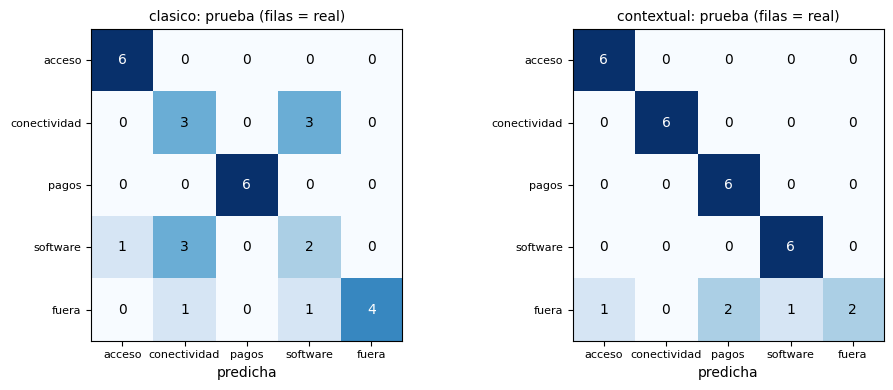

,id,texto,real,predicha
0,F031,¿Cuándo se paga el aguinaldo este año?,fuera_de_alcance,pagos
1,F033,"¿Cuándo se paga el aguinaldo este año? Ya reinicié y sigue igual, urge tantito.",fuera_de_alcance,pagos
2,F034,La silla de mi escritorio está rota.,fuera_de_alcance,software
3,F036,"La silla de mi escritorio está rota; ya reinicié y sigue igual, urge tantito.",fuera_de_alcance,acceso


Escenario de las actividades (4 clases, C=2): {'clasico': {'validation': 0.432, 'test': 0.604}, 'contextual': {'validation': 0.914, 'test': 1.0}}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (kind, r) in zip(axes, cls["resultados"].items()):
    cm = np.array(r["test"]["confusion"])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=6)
    short = [l.replace("fuera_de_alcance", "fuera") for l in LABELS_SISTEMA]
    ax.set_xticks(range(5), short, fontsize=8); ax.set_yticks(range(5), short, fontsize=8)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 3 else "black")
    ax.set_title(f"{kind}: prueba (filas = real)", fontsize=10); ax.set_xlabel("predicha")
plt.tight_layout(); plt.show()

errores = [p for p in cls["resultados"][cls["elegido"]]["test_predicciones"] if p["real"] != p["predicha"]]
display(pd.DataFrame(errores))
print("Escenario de las actividades (4 clases, C=2):", {k: {s: round(v, 3) for s, v in d.items()} for k, d in X.reproduccion_cuatro_clases(ctx).items()})

**Lectura.** Las familias de validación y prueba son peticiones que el modelo nunca vio. Por eso TF-IDF de palabras casi no transfiere: con macro-F1 de validación de 0.26, las palabras de contenido de una familia nueva no aparecen en entrenamiento y lo único compartido son las plantillas («Buen día…», «ya reinicié…»), presentes en todas las clases. Los n-gramas de caracteres lo mejoran (0.59) porque capturan raíces compartidas como *pag-* o *conex-*. MiniLM llega a **0.79 en validación** y **0.84 en prueba** (IC95 % 0.69-0.96, frente a 0.70 [0.53-0.83] del clásico): las paráfrasis quedan cerca en el espacio de embeddings aunque no compartan palabras.

**Modelo integrado: contextual (MiniLM + regresión logística, C=1).** Se elige con validación y supera al clásico en las 4 clases de soporte. Su costo es la latencia (≈14 ms frente a 0.2 ms por texto en CPU) y un modelo de 470 MB, aceptable para una mesa de ayuda. Su punto débil es la clase *fuera de alcance* (F1 0.50): «¿Cuándo se paga el aguinaldo?» se confunde con *pagos* porque comparte el tema del dinero. Por eso el sistema **no confía en esa etiqueta para descartar la búsqueda**: con «fuera de alcance» busca en toda la base y deja la decisión a la puerta de evidencia (sección 5).

Cada familia aporta tres variantes casi iguales, de modo que los 30 textos de prueba equivalen a solo 10 peticiones distintas: el intervalo real es más ancho que el del bootstrap por ejemplo.

## 4. Recuperación: qué documentos recupera y en qué orden

Se compara el ranking puro (sin filtro ni puerta) en las 39 consultas de desarrollo con respuesta: TF-IDF (1-2 gramas, sin acentos ni palabras funcionales), MiniLM (coseno) e híbrido `α·TF-IDF + (1-α)·MiniLM`. Se elige por **MRR@5 de desarrollo** y la prueba solo se reporta.

In [6]:
ret = X.comparar_recuperadores(ctx)
display(pd.DataFrame([{"recuperador": r["recuperador"], "alpha": r["alpha"],
                       "recall@3 dev": r["dev"]["recall_at_3"], "MRR@5 dev": r["dev"]["mrr_at_5"],
                       "recall@3 prueba": r["test"]["recall_at_3"], "MRR@5 prueba": r["test"]["mrr_at_5"]}
                      for r in ret["tabla"]]).round(3))
print("Elegido con desarrollo:", ret["elegido"])

,recuperador,alpha,recall@3 dev,MRR@5 dev,recall@3 prueba,MRR@5 prueba
0,tfidf,0.0,0.897,0.831,0.933,0.900
1,semantico,0.0,0.974,0.831,1.000,0.922
2,hibrido,0.3,1.000,0.949,1.000,1.000
3,hibrido,0.5,1.000,0.936,1.000,1.000
4,hibrido,0.7,1.000,0.936,0.933,0.950


Elegido con desarrollo: {'recuperador': 'hibrido', 'alpha': 0.3}


In [7]:
# Recalcular a mano recall@3 y MRR@5 para una consulta: ver el orden exacto.
from soporte_pln.recuperacion import make_retriever
for q, (name, alpha) in [(q, r) for q in ctx.dev_q if q["id"] in ("dev-21", "dev-09")
                         for r in [("tfidf", 0), ("hibrido", 0.3)]]:
    hits = search(make_retriever(name, ctx.chunks, ctx.encoder, alpha), q["query"], k=5)
    ranked = [h["chunk"].id for h in hits]
    pos = next((i for i, x in enumerate(ranked, 1) if x in q["relevant"]), None)
    print(f"{name:8s} {q['query']!r} -> {ranked} | relevante {q['relevant']} en posición {pos}: "
          f"recall@3={int(pos is not None and pos <= 3)}, MRR={1/pos if pos else 0:.3f}")
    assert E.ranking_metrics(ranked, q["relevant"])["mrr_at_5"] == (1 / pos if pos else 0)

tfidf    '¿Cuál red wifi deben usar los visitantes?' -> ['CON-01#s1', 'CON-01#s3', 'CON-01#s2', 'CON-01#s5', 'CON-02#s1'] | relevante ['CON-01#s1'] en posición 1: recall@3=1, MRR=1.000
hibrido  '¿Cuál red wifi deben usar los visitantes?' -> ['CON-01#s3', 'CON-01#s1', 'CON-02#s1', 'CON-01#s2', 'CON-03#s5'] | relevante ['CON-01#s1'] en posición 2: recall@3=1, MRR=0.500
tfidf    'MesaApp se congela cuando lo abro' -> ['SOF-02#s1', 'SOF-02#s7', 'SOF-02#s6', 'SOF-02#s4', 'SOF-02#s5'] | relevante ['SOF-02#s2'] en posición None: recall@3=0, MRR=0.000
hibrido  'MesaApp se congela cuando lo abro' -> ['SOF-02#s2', 'SOF-02#s1', 'SOF-02#s6', 'SOF-02#s5', 'SOF-01#s5'] | relevante ['SOF-02#s2'] en posición 1: recall@3=1, MRR=1.000


**Lectura.** El híbrido con α=0.3 queda primero en desarrollo (MRR@5 0.95 frente a 0.83 de TF-IDF y 0.83 de MiniLM) y en prueba encuentra el pasaje correcto en la **primera posición en las 15 consultas** (recall@3 = MRR@5 = 1.0). Las dos señales se complementan. TF-IDF acierta cuando la consulta repite términos del documento («American Express», «RFC»); MiniLM, cuando hay paráfrasis. En `dev-21` («MesaApp se congela cuando lo abro»), TF-IDF ni siquiera pone el pasaje correcto entre los 5 primeros, porque el corpus dice «congelada al iniciar», y el híbrido lo sube al primer lugar. El híbrido no gana siempre: en `dev-09` TF-IDF acierta y el híbrido baja el pasaje correcto al segundo lugar. En las 52 consultas de desarrollo, el híbrido mejora el orden en 9 consultas y lo empeora en 3.

## 5. Recorrido completo: solicitud → clasificación → búsqueda → respuesta

`responder(texto)` (`src/soporte_pln/sistema.py`) sigue estos pasos:

1. **Validar** la entrada: debe ser texto, no estar vacía, tener ≤1000 caracteres y contener palabras.
2. **Proteger** los datos: oculta correos, teléfonos y números de tarjeta antes de clasificar o registrar.
3. **Clasificar** con MiniLM + RL. La etiqueta decide la **canalización**: cola de la categoría, otra área o revisión si la confianza es menor de 0.5. Con una categoría de soporte segura, la búsqueda se limita a esa categoría y a los artículos generales.
4. **Buscar** los 3 mejores pasajes con el recuperador híbrido.
5. **Puerta de evidencia**, recorriendo los pasajes en orden de ranking. Se acepta el primero que (a) no deje ningún término de la consulta **ausente de todo el corpus**, (b) cubra al menos el 60 % de los términos informativos y (c) tenga una puntuación de al menos 0.5. Estos umbrales se calibraron con desarrollo y quedaron congelados en `resultados/politica.json`.
6. **Responder.** La respuesta es **extractiva**: copia literalmente las oraciones del pasaje que más términos comparten con la consulta, cita documento, sección, archivo e ID, y no genera texto nuevo. Si ningún pasaje pasa la puerta, **se abstiene** y canaliza la solicitud.

In [8]:
politica = leer_politica()
print("Archivos cambiados desde que se congeló la política:", verificar_huellas(politica) or "ninguno")
print("Política:", {k: v for k, v in politica["config"].items() if k != "synonyms"}, "| puerta:", politica["puerta"])
sistema = cargar_sistema(encoder=ctx.encoder)   # sin registro en el notebook

Archivos cambiados desde que se congeló la política: ninguno
Política: {'retriever': 'hibrido', 'alpha': 0.3, 'tau': 0.5, 'min_coverage': 0.6, 'oov_veto': True, 'routing': True, 'gate': True, 'route_min_conf': 0.5, 'k': 3} | puerta: relajada_con_veto


In [9]:
# Caso 1: respuesta con fuente verificable.
r = sistema.responder("Buen día, ¿cuántas sesiones puedo tener abiertas al mismo tiempo? Mi correo es ana.perez@example.com")
print(format_result(r))
print("\nConsulta tal como la procesa el sistema:", r["consulta_protegida"])
pasaje = next(c for c in ctx.chunks if c.id == r["respuesta"]["fuente"]["id"])
print("\nPasaje completo citado:\n", pasaje.texto)
assert all(s in pasaje.texto for s in SENTENCE.split(r["respuesta"]["texto"]))
print("\nComprobación: cada oración de la respuesta aparece literalmente en el pasaje citado.")

Estado: respondida
Clasificación: fuera_de_alcance (confianza 0.55) -> otra_area
Búsqueda (hibrido, categorías: todas):
  1. ✔ ACC-03#s4 «Sesiones abiertas en varios dispositivos» score=0.605 · evidencia_suficiente
  2. ✘ ACC-03#s2 «La sesión caduca mientras trabajo» score=0.404 · cobertura_insuficiente
  3. ✘ GEN-01#s1 «Horario de atención» score=0.334 · cobertura_insuficiente
Respuesta: Puedes tener hasta tres sesiones abiertas al mismo tiempo. Al abrir una cuarta sesión, se cierra automáticamente la más antigua.
Fuente: ACC-03 «Cuentas bloqueadas y sesiones que se cierran» › «Sesiones abiertas en varios dispositivos» (acc03_bloqueo_sesiones.md, ACC-03#s4)
Tipo de respuesta: extractiva (oraciones copiadas literalmente del pasaje citado)

Consulta tal como la procesa el sistema: Buen día, ¿cuántas sesiones puedo tener abiertas al mismo tiempo? Mi correo es [CORREO]

Pasaje completo citado:
 Puedes tener hasta tres sesiones abiertas al mismo tiempo. Al abrir una cuarta sesión, se cierr

In [10]:
# Caso 2: abstención porque falta evidencia (el corpus no menciona Linux).
r = sistema.responder("¿La VPN funciona en Linux?")
print(format_result(r))
print("\nDetalle de la puerta en el primer candidato:", {k: r["busqueda"]["ranking"][0][k] for k in ["terminos", "desconocidos", "cobertura", "score"]})

Estado: abstencion
Clasificación: conectividad (confianza 0.59) -> cola_conectividad
Búsqueda (hibrido, categorías: ['conectividad', 'general']):
  1. ✘ CON-02#s1 «Para qué sirve la VPN» score=0.578 · termino_desconocido_en_corpus
  2. ✘ CON-02#s2 «Conectarse a la VPN desde casa» score=0.502 · termino_desconocido_en_corpus
  3. ✘ CON-02#s4 «La velocidad baja cuando activo la VPN» score=0.487 · termino_desconocido_en_corpus
Respuesta: No encuentro evidencia suficiente en la base de conocimiento para responder. Tu solicitud se canaliza a la cola de conectividad para que la atienda una persona.

Detalle de la puerta en el primer candidato: {'terminos': ['funciona', 'linux', 'vpn'], 'desconocidos': ['linux'], 'cobertura': 0.6667, 'score': 0.5783}


In [11]:
# Entrada válida frente a entradas inválidas.
casos = ["¿Qué significa la luz roja del router?", "", "   ", "12345 ???", None, "x" * 1500]
tabla = []
for c in casos:
    out = sistema.responder(c)
    tabla.append({"entrada": repr(c)[:40], "estado": out["estado"], "mensaje": out["mensaje"][:110]})
display(pd.DataFrame(tabla))

,entrada,estado,mensaje
0,'¿Qué significa la luz roja del router?',respondida,Una luz roja fija significa que el router no recibe servicio del proveedor de internet...
1,'',entrada_invalida,La solicitud no es válida: la solicitud está vacía.
2,' ',entrada_invalida,La solicitud no es válida: la solicitud está vacía.
3,'12345 ???',entrada_invalida,La solicitud no es válida: no contiene palabras.
4,None,entrada_invalida,La solicitud no es válida: se esperaba texto y se recibió NoneType.
5,'xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx,entrada_invalida,La solicitud no es válida: supera 1000 caracteres.


**Nota sobre el caso 1.** El clasificador se equivocó: etiquetó la consulta como *fuera de alcance* con confianza 0.55. Aun así, el sistema respondió bien, porque con esa etiqueta busca en toda la base y la puerta de evidencia decide. Esta es la decisión de diseño de la sección 3 funcionando.

**Interfaz y almacenamiento.** La interfaz es una **función** (`soporte_pln.api.responder`) y un comando (`scripts/responder.py "texto"`). Una función se puede probar con `pytest`, no necesita servidor ni credenciales y la usa igual el notebook que una API futura. No hay base de datos: el corpus son archivos Markdown versionados, que se pueden auditar y citar, y los vectores se calculan en memoria al arrancar (80 pasajes, unos segundos en CPU). El único archivo que escribe el sistema es un registro opcional, `registros/consultas.jsonl`, con **datos mínimos**: fecha, huella SHA-256 truncada de la consulta ya protegida, longitud, estado, etiqueta y fuente. **Nunca guarda el texto de la consulta.**

## 6. Evaluación y mejora

### 6.1 Métricas del sistema completo (recalculadas)

* **Correctas con cita**: consultas con respuesta en las que el sistema respondió citando un pasaje relevante.
* **Sin respaldo**: respuestas emitidas cuya cita no es relevante. Es el error que más importa evitar.
* **Recall de abstención**: proporción de las consultas sin evidencia en las que el sistema se abstuvo.
* **Precisión de cita**: proporción de las respuestas emitidas que citan un pasaje relevante.

In [12]:
final = X.Config(**politica["config"])
clf = sistema.classifier
vivo = {s: X.evaluar_sistema(clf, ctx.chunks, ctx.encoder, final, q) for s, q in [("desarrollo (52)", ctx.dev_q), ("prueba (20)", ctx.test_q)]}
display(pd.DataFrame({s: v["metricas"] for s, v in vivo.items()}).T.round(3))
guardado = json.loads((RES / "resumen.json").read_text(encoding="utf-8"))["ablaciones"]["sistema_completo"]
assert vivo["prueba (20)"]["metricas"] == guardado["test"], "No coincide con resultados/resumen.json"
print("Coincide con lo guardado por scripts/evaluar.py.")
det = pd.DataFrame(vivo["prueba (20)"]["detalle"])[["id", "query", "answerable", "etiqueta_predicha", "estado", "fuente", "cita_valida", "motivo"]]
display(det)

,n,respondibles,sin_evidencia,respuestas_correctas_con_cita,tasa_respuesta_correcta,respuestas_sin_respaldo,precision_de_cita,recall_abstencion,tasa_abstencion_falsa
desarrollo (52),52.0,39.0,13.0,19.0,0.487,0.0,1.000,1.0,0.513
prueba (20),20.0,15.0,5.0,6.0,0.400,1.0,0.857,0.8,0.600


Coincide con lo guardado por scripts/evaluar.py.


,id,query,answerable,etiqueta_predicha,estado,fuente,cita_valida,motivo
0,test2-01,"Me llegó un aviso de que mi contraseña va a vencer, ¿con cuánta anticipación avisan?",True,acceso,abstencion,None,False,termino_desconocido_en_corpus
1,test2-02,¿Cuántos códigos de respaldo me dan al activar el segundo factor?,True,acceso,respondida,ACC-02#s3,True,evidencia_suficiente
2,test2-03,Rechacé varias notificaciones de aprobación y ahora no me deja entrar,True,acceso,abstencion,None,False,termino_desconocido_en_corpus
3,test2-04,¿Cuántos intentos fallidos se permiten antes de que se bloquee la cuenta?,True,acceso,respondida,ACC-03#s1,True,evidencia_suficiente
4,test2-05,"Se me olvidó la clave de mi cuenta, ¿qué hago?",True,acceso,abstencion,None,False,termino_desconocido_en_corpus
5,test2-06,¿Cuánto tiempo tarda el router en volver a iniciar después de desconectarlo?,True,conectividad,respondida,CON-03#s3,True,evidencia_suficiente
6,test2-07,En la sala del sótano casi no agarra la señal,True,conectividad,abstencion,None,False,termino_desconocido_en_corpus
7,test2-08,¿Qué servidor de VPN me conviene si trabajo desde el sur del país?,True,conectividad,abstencion,None,False,termino_desconocido_en_corpus
8,test2-09,¿A qué hora conviene programar descargas grandes?,True,software,abstencion,None,False,termino_desconocido_en_corpus
9,test2-10,¿Cuánto tarda en aparecer el comprobante después de pagar?,True,pagos,respondida,PAG-01#s1,True,evidencia_suficiente


### 6.2 Historia de la puerta de evidencia (protocolo de prueba)

1. **Iteración 1.** La puerta del demo de clase exige que **todos** los términos estén en el pasaje. Con las 32 consultas de desarrollo la comparamos con dos alternativas (cobertura relajada, y cobertura relajada con veto de términos ausentes del corpus), calibramos τ y la cobertura, congelamos la política y la evaluamos **una vez** en `consultas_test_v1.json`. Los resultados están en `resultados/prueba_v1_retirada/`.
2. Esa prueba quedó **retirada** y pasó a desarrollo. Redactamos una prueba nueva (`consultas_test.json`) y registramos su huella **antes** de intentar otra mejora.
3. **Iteración 2.** Para corregir las abstenciones falsas intentamos un diccionario de sinónimos (`datos/sinonimos.json`), construido solo con fallos de desarrollo. En desarrollo **empeoró** (de 19 a 14 respuestas correctas): un sinónimo dejó pasar un pasaje equivocado y la regla de 0 respuestas sin respaldo obligó a subir τ. Por la regla declarada (elegir con desarrollo) se descartó. Una primera ejecución lo había dejado fijo por error como puerta final; lo corregimos para que la elección también salga de desarrollo. La prueba de cada puerta se reporta, pero no se usó para decidir.
4. Con las 52 consultas de desarrollo, la calibración volvió a elegir la **misma** configuración de la iteración 1 (híbrido α=0.3, τ=0.5, cobertura 0.6 y veto), que es la que se evalúa en la prueba vigente.

In [13]:
puertas = json.loads((RES / "puerta.json").read_text(encoding="utf-8"))
v1 = json.loads((RES / "prueba_v1_retirada" / "resumen.json").read_text(encoding="utf-8"))["puertas"]
cols = ["respuestas_correctas_con_cita", "respuestas_sin_respaldo", "recall_abstencion", "tasa_abstencion_falsa"]
filas = []
for g in ["estricta", "cobertura_relajada", "relajada_con_veto", "veto_con_sinonimos"]:
    cfg = puertas[g]["config"]
    fila = {"puerta": g, "τ": cfg["tau"], "cobertura": cfg["min_coverage"], "veto": cfg["oov_veto"]}
    fila |= {f"dev52 {k[:22]}": puertas[g]["dev"][k] for k in cols[:2]}
    if g in v1:
        fila |= {"prueba v1 correctas (de 15)": v1[g]["test"][cols[0]], "prueba v1 sin respaldo": v1[g]["test"][cols[1]]}
    fila |= {"prueba vigente correctas (de 15)": puertas[g]["test"][cols[0]], "prueba vigente sin respaldo": puertas[g]["test"][cols[1]],
             "prueba vigente recall abst.": puertas[g]["test"][cols[2]]}
    filas.append(fila)
display(pd.DataFrame(filas).set_index("puerta"))
print("Puerta elegida con desarrollo:", json.loads((RES / "resumen.json").read_text(encoding="utf-8"))["puerta_final"])

,τ,cobertura,veto,dev52 respuestas_correctas_c,dev52 respuestas_sin_respald,prueba v1 correctas (de 15),prueba v1 sin respaldo,prueba vigente correctas (de 15),prueba vigente sin respaldo,prueba vigente recall abst.
puerta,,,,,,,,,,
estricta,0.4,1.0,False,8,0,1.0,0.0,2,0,1.0
cobertura_relajada,0.6,0.5,False,14,0,2.0,0.0,2,0,1.0
relajada_con_veto,0.5,0.6,True,19,0,5.0,0.0,6,1,0.8
veto_con_sinonimos,0.6,0.5,True,14,0,NaN,NaN,1,0,1.0


Puerta elegida con desarrollo: relajada_con_veto


### 6.3 Mejora comprobada

Pasar de la **puerta estricta** a la **cobertura relajada con veto** mantiene 0 respuestas sin respaldo en desarrollo y en la prueba v1, y multiplica las respuestas correctas:

| Conjunto | Estricta (demo) | Relajada + veto |
|---|---|---|
| Desarrollo (32 consultas originales) | 7/24 | 14/24 |
| Prueba v1 (retirada, usada una vez) | 1/15, 0 sin respaldo | **5/15, 0 sin respaldo** |
| Prueba vigente | 2/15, 0 sin respaldo | **6/15, 1 sin respaldo** |

La mejora se repite en dos pruebas independientes (+4 respuestas correctas en cada una). El costo aparece en la prueba vigente: una respuesta sin respaldo, que se analiza en 6.4. El veto es el componente que permite relajar la cobertura. Sin él (fila `cobertura_relajada`), relajar la cobertura dejaba pasar consultas como «¿La VPN funciona en Linux?» y la regla de selección tuvo que subir τ hasta 0.6, lo que acabó con casi todas las respuestas.

In [14]:
# Análisis de fallos en la prueba vigente.
def traza(texto):
    out = sistema.responder(texto)
    print(format_result(out))
    for h in out["busqueda"]["ranking"]:
        print(f"   {h['id']}: términos={h['terminos']} faltan={h['faltantes']} desconocidos={h['desconocidos']} cobertura={h['cobertura']}")
    print()

# (a) Respuesta SIN respaldo: la pregunta pide un máximo y el pasaje solo da un mínimo.
traza("¿Cuántos caracteres puede tener como máximo mi contraseña?")
# (b) Abstención falsa típica: un coloquialismo ausente del corpus activa el veto.
traza("Se me olvidó la clave de mi cuenta, ¿qué hago?")

Estado: respondida
Clasificación: acceso (confianza 0.45) -> revision
Búsqueda (hibrido, categorías: todas):
  1. ✔ ACC-01#s2 «Requisitos de una contraseña nueva» score=0.572 · evidencia_suficiente
  2. ✘ ACC-01#s3 «Caducidad de la contraseña» score=0.362 · cobertura_insuficiente
  3. ✘ ACC-01#s1 «Restablecer una contraseña olvidada» score=0.318 · cobertura_insuficiente
Respuesta: La contraseña nueva debe tener al menos 12 caracteres e incluir una letra mayúscula, una letra minúscula y un número. Si el portal rechaza la contraseña nueva, revisa estos requisitos uno por uno: el motivo más frecuente es reutilizar una contraseña anterior o escribir menos de 12 caracteres.
Fuente: ACC-01 «Restablecer y cambiar la contraseña» › «Requisitos de una contraseña nueva» (acc01_contrasena.md, ACC-01#s2)
Tipo de respuesta: extractiva (oraciones copiadas literalmente del pasaje citado)
   ACC-01#s2: términos=['caracteres', 'contrasena', 'maximo', 'tener'] faltan=['maximo'] desconocidos=[] cobertura=

**Análisis del fallo (a): respuesta sin respaldo.** Ante «¿Cuántos caracteres puede tener **como máximo** mi contraseña?», el ranking es correcto en el sentido temático: el primer pasaje es ACC-01#s2, «Requisitos de una contraseña nueva». Todos los términos existen en el corpus y 3 de 4 (*caracteres*, *contraseña*, *tener*) están en el pasaje; solo falta *máximo*. Con una cobertura de 0.75 ≥ 0.6 y una puntuación de 0.57 ≥ 0.5, la puerta lo acepta. Pero el pasaje dice «**al menos** 12 caracteres» y no fija ningún máximo. La puerta **mide superposición de términos, no implicación**: no distingue «mínimo» de «máximo», ni una pregunta que el pasaje responde de otra que solo toca el mismo tema. Así ocurre el error más grave: el usuario podría entender que el máximo es 12.

**Fallo (b): abstención falsa.** En «Se me olvidó la **clave** de mi cuenta», *clave* no aparece en el corpus, que siempre dice *contraseña*. El veto considera que no hay evidencia posible y se abstiene aunque ACC-01#s1 ocupe el primer lugar y responda exactamente. En la prueba, **7 de las 9 abstenciones falsas** se deben al veto por palabras coloquiales o conjugaciones que no aparecen en el corpus (*anticipación*, *rechacé*, *clave*, *agarra*, *conviene* dos veces, *salió*); las otras 2 quedan por debajo de τ=0.5. En las 7, el pasaje correcto ocupaba el primer lugar del ranking. El diccionario de sinónimos de la iteración 2 corregía casos de desarrollo pero no generalizaba, y en desarrollo introdujo un error.

**Siguiente mejora propuesta (no aplicada):** sustituir la cobertura léxica por un verificador de **implicación textual** multilingüe (NLI o cross-encoder) que juzgue si el pasaje responde la pregunta. Para evaluarlo hace falta una prueba nueva, porque esta ya se usó.

## 7. Ablación: retirar un componente y dejar todo lo demás igual

Mismo clasificador, mismo recuperador, mismos umbrales y mismas consultas; en cada variante se retira **un** componente.

In [15]:
abl = X.ablaciones(ctx, clf, final)
filas = []
for nombre, v in abl.items():
    for s, nom in [("dev", "desarrollo"), ("test", "prueba")]:
        m = v[s]["metricas"]
        filas.append({"variante": nombre, "conjunto": nom, **{k: m[k] for k in ["respuestas_correctas_con_cita", "respuestas_sin_respaldo", "precision_de_cita", "recall_abstencion", "tasa_abstencion_falsa"]}})
display(pd.DataFrame(filas).round(3).set_index(["variante", "conjunto"]))

respuestas_correctas_con_cita  \
variante                     conjunto                                    
sistema_completo             desarrollo                             19   
                             prueba                                  6   
sin_puerta_de_evidencia      desarrollo                             35   
                             prueba                                 15   
sin_filtro_por_clasificacion desarrollo                             19   
                             prueba                                  6   

                                         respuestas_sin_respaldo  \
variante                     conjunto                              
sistema_completo             desarrollo                        0   
                             prueba                            1   
sin_puerta_de_evidencia      desarrollo                       17   
                             prueba                            5   
sin_filtro_por_clasificacion desarrollo                        0   
                             prueba                            1   

                                         precision_de_cita  recall_abstencion  \
variante                     conjunto                                           
sistema_completo             desarrollo              1.000                1.0   
                             prueba                  0.857                0.8   
sin_puerta_de_evidencia      desarrollo              0.673                0.0   
                             prueba                  0.750                0.0   
sin_filtro_por_clasificacion desarrollo              1.000                1.0   
                             prueba                  0.857                0.8   

                                         tasa_abstencion_falsa  
variante                     conjunto                           
sistema_completo             desarrollo                  0.513  
                             prueba                      0.600  
sin_puerta_de_evidencia      desarrollo                  0.000  
                             prueba                      0.000  
sin_filtro_por_clasificacion desarrollo                  0.513  
                             prueba                      0.600

**Lectura.**

* **Sin puerta de evidencia**: el sistema responde siempre con el primer pasaje. Como el ranking es muy bueno, acierta 15/15 en prueba y 35/39 en desarrollo, pero responde también **las 5 consultas de prueba sin evidencia** (17 respuestas sin respaldo en desarrollo, recall de abstención 0). La puerta es lo único que hace que el sistema diga «no sé». El precio es alto: pasa de 15 a 6 respuestas correctas en prueba. El compromiso queda a la vista: la puerta actual es **segura pero demasiado conservadora**.
* **Sin filtro por clasificación**: las métricas son **idénticas**. El recuperador híbrido ya pone primero pasajes de la categoría correcta, así que filtrar no cambia ninguna decisión en estas consultas. El aporte medible del clasificador está en la **canalización** (qué cola o área recibe la solicitud cuando el sistema se abstiene) y no en la búsqueda. Que la búsqueda en toda la base ante «fuera de alcance» no empeore nada justifica esa decisión de diseño.

## 8. Reproducibilidad

* `pip install -r requirements.txt` con las versiones fijadas (Python 3.11, CPU). El modelo se descarga con una revisión fija (`scripts/descargar_modelo.py`).
* `python scripts/evaluar.py` regenera todos los JSON y figuras de `resultados/` en unos 2 minutos. `python -m pytest` ejecuta 24 pruebas: datos, entradas, métricas y recorrido completo.
* `resultados/politica.json` guarda las huellas de los datos, la base y el código con que se congeló la política. La prueba `test_politica_corresponde_a_los_archivos_actuales` falla si alguno cambió.
* Se verificó el README desde una copia limpia de la carpeta, con un entorno nuevo (ver `README.md`, sección «Verificación»).

In [16]:
print("Huellas de los datos:")
for f, h in resumen["sha256"].items():
    print(f"  {f:28s} {h[:16]}…")
print("Política congelada el", politica["fecha_utc"], "| archivos cambiados:", verificar_huellas(politica) or "ninguno")

Huellas de los datos:
  solicitudes.csv              923d4fd289a7f12f…
  fuera_de_alcance.csv         4dd2b716994a60e1…
  consultas_dev.json           3a0998b8c69704fb…
  consultas_test_v1.json       ca519efdbf2e9930…
  consultas_test.json          39a10f69062b3781…
  sinonimos.json               e4ba4db4dab7e094…
Política congelada el 2026-11-18T01:41:25+00:00 | archivos cambiados: ninguno


## 9. Límites

* **Datos sintéticos y pocos.** Solo 10 peticiones distintas en la prueba de clasificación (30 textos) y 20 consultas en la prueba de recuperación: una sola consulta mueve la tasa 6.7 puntos. Las consultas las redactó el mismo equipo que escribió la base, aunque la prueba vigente se redactó antes de diseñar la versión final.
* **La puerta es léxica.** No entiende negación, cantidades ni la diferencia entre mínimo y máximo (fallo 6.4a), y castiga los coloquialismos (6.4b). Es segura en desarrollo (0 respuestas sin respaldo), pero en prueba tuvo 1 respuesta sin respaldo y 9 abstenciones falsas de 15.
* **Fuera de alcance** es la clase más débil del clasificador (F1 0.50); por eso no se usa para cortar la búsqueda.
* **Respuesta extractiva.** Copia oraciones; no resume ni combina pasajes. Si la respuesta está repartida entre dos secciones, solo cita una.
* La base es ficticia y está fija; actualizarla obliga a recalibrar y a redactar otra prueba.